# 🌱 Lesson 5: Feature Selection
**Phase 2 · Data Preprocessing & Feature Engineering** &nbsp;|&nbsp; ⏱ about 3 hours &nbsp;|&nbsp; 📚 Prerequisite: Lesson 04

> *Add features until the model gets confused; then take the confusing ones away.*

## 🎯 By the end of this lesson you will be able to
- Explain why *more features is not always better* (noise, redundancy, the curse of dimensionality).
- Choose between filter, wrapper and embedded methods.
- Apply correlation, VIF, F-test, mutual information, RFE/RFECV, tree/permutation importance and Lasso.
- Reduce dimensionality with PCA and decide how many components to keep.
- Use 'canary' noise features to sanity-check any selection method.

---

In [1]:
import sys
sys.path.append("../utils")            # lets us import course_utils.py and agri_prep.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from course_utils import *             # load_raw_farm, profile, setup_plots, ...

setup_plots()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.random.seed(42)

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import Ridge, LinearRegression

# Part 1 · Why select features?

After Lesson 4 we have *many* columns. Tempting thought: *"give the model everything, let it sort it out."* Three problems:

| Problem | Explanation |
|---|---|
| **Noise** | Irrelevant features give the model more ways to find coincidences that don't generalise (overfitting). |
| **Redundancy** | Near-duplicate columns (°C and °F) add cost and make linear-model coefficients unstable. |
| **Cost & clarity** | More columns = slower training, more data to collect in production, harder to explain. |

### The curse of dimensionality: felt, not just read
We'll predict *maize yield* with k-Nearest Neighbours using 5 genuinely useful features, then add more and more **pure noise** columns:

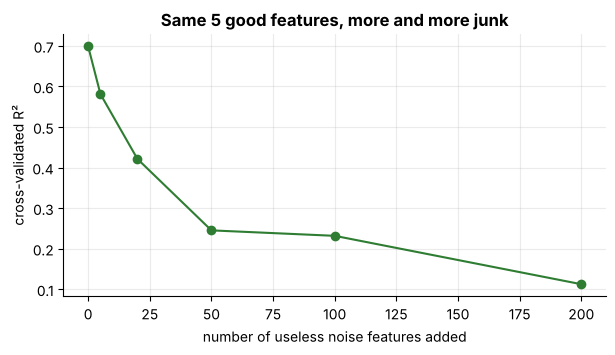

,0,5,20,50,100,200
R²,0.699,0.581,0.421,0.245,0.232,0.112


In [3]:
from sklearn.neighbors import KNeighborsRegressor

fe0 = build_farm_features(load_lesson_clean())
maize = fe0[fe0["crop"] == "Maize"].dropna(subset=["rain_gap_sq", "temp_gap_sq", "ph_gap_sq", "log_fert", "organic_matter_pct"])
good = maize[["rain_gap_sq", "temp_gap_sq", "ph_gap_sq", "log_fert", "organic_matter_pct"]].reset_index(drop=True)
ym = np.log(maize["yield_t_ha"]).reset_index(drop=True)

rng0 = np.random.default_rng(0)
results = {}
for n_noise in [0, 5, 20, 50, 100, 200]:
    Xn = pd.concat([good, pd.DataFrame(rng0.normal(size=(len(good), n_noise)))], axis=1)
    Xn.columns = Xn.columns.astype(str)
    results[n_noise] = cross_val_score(make_pipeline(StandardScaler(), KNeighborsRegressor(10)), Xn, ym, cv=5, scoring="r2").mean()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(list(results), list(results.values()), marker="o"); ax.set_xlabel("number of useless noise features added")
ax.set_ylabel("cross-validated R²"); ax.set_title("Same 5 good features, more and more junk"); plt.show()
pd.Series(results).round(3).to_frame("R²").T

The five useful features never changed, yet accuracy collapses as noise piles up. Each junk column adds a dimension in which "neighbours" are chosen at random. **Selection is not about speed; it protects accuracy.**

## The three families of selection methods

| Family | How it works | Examples | Speed | Considers feature interactions? |
|---|---|---|---|---|
| **Filter** | Scores each feature with a statistic, *before* any model | correlation, F-test, mutual information, variance threshold | ⚡ fast | ❌ |
| **Wrapper** | Trains a model repeatedly on feature subsets | RFE, RFECV, forward/backward selection | 🐢 slow | ✅ |
| **Embedded** | Selection happens *during* training | Lasso (L1), tree importances | ⚙️ medium | ✅ |

> A fourth idea, **dimensionality reduction** (PCA), doesn't pick features: it *builds* fewer new ones from all of them.

---
# Part 2 · Set up our feature table
We assemble numeric features (Lesson 4 recipes) plus crop dummies. Two deliberate additions for teaching:

- 🐤 **Three "canary" columns of pure random noise.** A selector that ranks a canary highly is not to be trusted. (Named after the canary in the coal mine.)
- 🌡️ **`temp_f`**: temperature in Fahrenheit: a perfectly redundant copy of `avg_temp_c`.

> Reminder: we median-impute on the whole data here for convenience. The leak-safe version arrives in Lessons 6–7.

In [4]:
from sklearn.impute import SimpleImputer

fe = build_farm_features(load_lesson_clean())          # Lesson-04 recipes (see utils/course_utils.py)

NUM = ["rainfall_mm", "avg_temp_c", "soil_ph", "nitrogen_ppm", "phosphorus_ppm", "potassium_ppm",
       "organic_matter_pct", "fertilizer_kg_ha", "farm_size_ha", "irrigation", "plant_month", "plant_year",
       "grow_days", "npk_total", "n_to_p_ratio", "moisture_index", "fert_x_irrig", "log_fert", "log_farm_size",
       "rain_gap_sq", "temp_gap_sq", "ph_gap_sq", "pest_ord", "exp_ord"]

# median-impute (for this lesson only - on the whole data; the pipeline version comes in Lesson 7)
X_num = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(fe[NUM]), columns=NUM, index=fe.index)
crops = pd.get_dummies(fe["crop"], prefix="crop", dtype=float)

rng = np.random.default_rng(0)
canaries = pd.DataFrame(rng.normal(size=(len(fe), 3)), columns=["noise_1", "noise_2", "noise_3"], index=fe.index)

X = pd.concat([X_num, crops, canaries], axis=1)
X["temp_f"] = X["avg_temp_c"] * 9 / 5 + 32               # a 'helpful colleague' added Fahrenheit...
y = np.log(fe["yield_t_ha"])                              # regression target
y_cls = (fe["yield_t_ha"] > fe.groupby("crop")["yield_t_ha"].transform("median")).astype(int)   # 'above-median for its crop'

In [5]:
print("Feature matrix:", X.shape, "| target: log(yield)")
list(X.columns)

Feature matrix: (2329, 33) | target: log(yield)


['rainfall_mm',
 'avg_temp_c',
 'soil_ph',
 'nitrogen_ppm',
 'phosphorus_ppm',
 'potassium_ppm',
 'organic_matter_pct',
 'fertilizer_kg_ha',
 'farm_size_ha',
 'irrigation',
 'plant_month',
 'plant_year',
 'grow_days',
 'npk_total',
 'n_to_p_ratio',
 'moisture_index',
 'fert_x_irrig',
 'log_fert',
 'log_farm_size',
 'rain_gap_sq',
 'temp_gap_sq',
 'ph_gap_sq',
 'pest_ord',
 'exp_ord',
 'crop_Beans',
 'crop_Maize',
 'crop_Potato',
 'crop_Sorghum',
 'crop_Wheat',
 'noise_1',
 'noise_2',
 'noise_3',
 'temp_f']

---
# Part 3 · Correlation-based selection

## 3.1 Feature ↔ feature: redundancy
Pearson correlation *r* runs from −1 to +1. We care about **|r|**. Two features with |r| near 1 say the same thing twice.

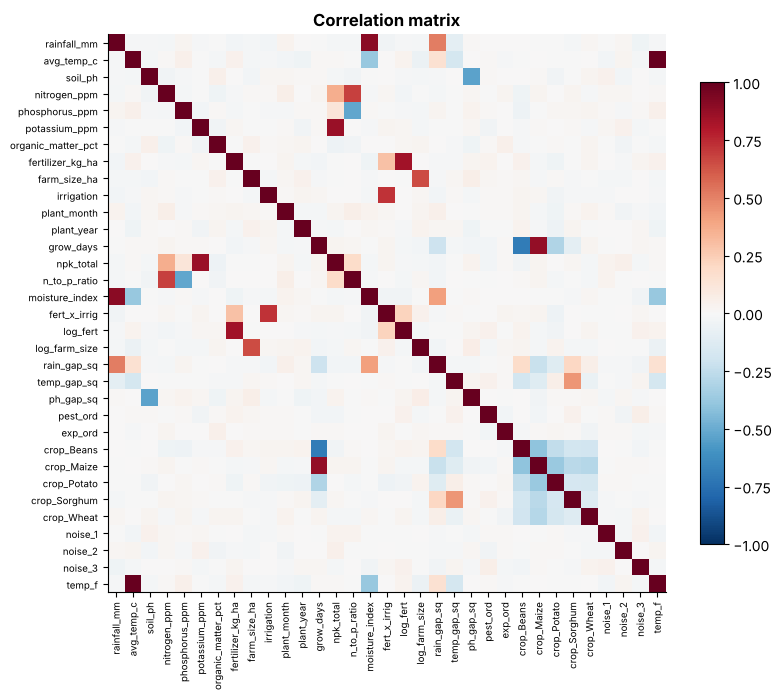

In [6]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7); ax.grid(False)
plt.colorbar(im, shrink=.8); ax.set_title("Correlation matrix"); plt.show()

Dark red/blue off-diagonal squares = redundancy. Let's list the offending pairs and decide what to drop:

In [7]:
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))      # upper triangle: each pair once
pairs = upper.stack()
pairs[pairs > 0.8].sort_values(ascending=False).round(3).to_frame("|r|")

,,|r|
avg_temp_c,temp_f,1.000
rainfall_mm,moisture_index,0.902
grow_days,crop_Maize,0.879
potassium_ppm,npk_total,0.863
fertilizer_kg_ha,log_fert,0.840


In [8]:
def drop_correlated(X, threshold=0.9):
    """Names to drop: for every highly correlated pair, drop the LATER column."""
    c = X.corr().abs()
    u = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
    return [col for col in u.columns if (u[col] > threshold).any()]

dropped = drop_correlated(X, 0.9)
print("drop:", dropped)
X_nr = X.drop(columns=dropped)
print("features:", X.shape[1], "→", X_nr.shape[1])

drop: ['moisture_index', 'temp_f']
features: 33 → 31


`temp_f` (as expected, r = 1.0 with `avg_temp_c`) and a few engineered features that largely repeat their ingredients are flagged. Always *look* at the list: engineered ratios like `moisture_index` are *meant* to be related to their parents; the question is whether they add information beyond them (Part 4 will tell).

## 3.2 Variance Inflation Factor (VIF): multicollinearity for linear models
VIF asks: *"how well can the other features predict this one?"* Regress each feature on all the others; $\text{VIF} = 1/(1-R^2)$. Rule of thumb: **> 5–10 = trouble**.

In [9]:
def vif(Xdf):
    out = {}
    for col in Xdf.columns:
        others = Xdf.drop(columns=col)
        r2 = LinearRegression().fit(others, Xdf[col]).score(others, Xdf[col])
        out[col] = 1 / (1 - r2) if r2 < 0.999999 else np.inf
    return pd.Series(out).sort_values(ascending=False)

vif(X.drop(columns=[c for c in X.columns if c.startswith("crop_")])).head(8).round(1).to_frame("VIF")

,VIF
avg_temp_c,inf
temp_f,inf
moisture_index,19.8
rainfall_mm,17.4
npk_total,10.3
potassium_ppm,8.8
nitrogen_ppm,4.1
n_to_p_ratio,3.8


`temp_f`/`avg_temp_c` show astronomically high VIF (they're the same variable). Crop dummies are excluded here since *all* dummies of one variable always sum to 1 (the dummy trap!).

## 3.3 Feature ↔ target: relevance: and its blind spot
Correlation with the target is the simplest relevance score:

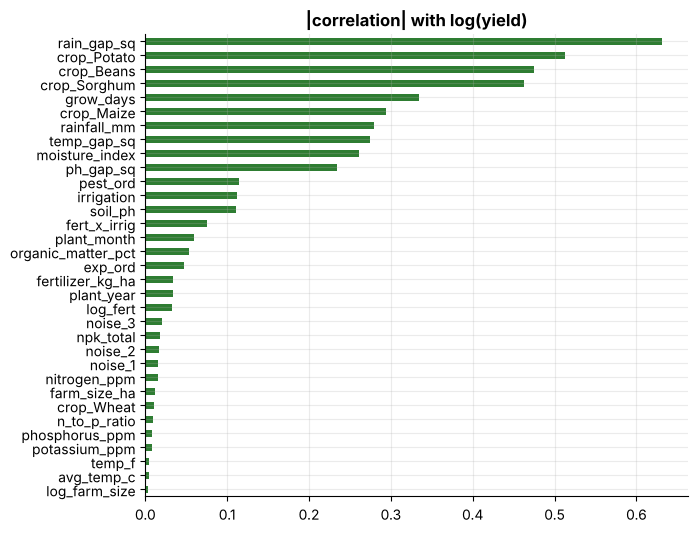

In [10]:
rel = X.corrwith(y).abs().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 6))
rel.sort_values().plot.barh(ax=ax, color="#2E7D32"); ax.set_title("|correlation| with log(yield)"); plt.show()

Now zoom in on **one crop**, where the rainfall story is clean. Maize has an ideal rainfall of about 650 mm: yields drop when it's drier *or* wetter. Compare the straight-line correlation of raw rainfall with that of its engineered cousin, and with mutual information (which sees curves):

In [11]:
from sklearn.feature_selection import mutual_info_regression
mz = X[fe["crop"] == "Maize"]
ymz = y[fe["crop"] == "Maize"]
cols4 = ["rainfall_mm", "rain_gap_sq", "avg_temp_c", "temp_gap_sq"]
pd.DataFrame({"|correlation|": mz[cols4].corrwith(ymz).abs(),
              "mutual information": mutual_info_regression(mz[cols4], ymz, random_state=0)}, index=cols4).round(3)

,|correlation|,mutual information
rainfall_mm,0.100,0.053
rain_gap_sq,0.315,0.060
avg_temp_c,0.313,0.171
temp_gap_sq,0.420,0.158


For maize, raw rainfall has a **weak** linear correlation with yield (≈ 0.1) even though rainfall is one of its main drivers: the relationship is a *hill*, and a straight line can't describe a hill. The engineered `rain_gap_sq` captures it far better (≈ 0.3), and the same story holds for temperature.

> **Lesson:** a low correlation is *not* proof that a feature is useless. Use methods that detect non-linear relations too (Parts 4–6).

---
# Part 4 · Statistical feature selection (filters)

## 4.1 Variance threshold: the cheapest filter
A column that barely varies cannot distinguish anything.

In [12]:
from sklearn.feature_selection import VarianceThreshold

X_test_v = X.assign(constant_col=1.0, almost_constant=np.where(np.arange(len(X)) % 500 == 0, 1.0, 0.0))
vt = VarianceThreshold(threshold=0.01).fit(X_test_v)
print("removed by VarianceThreshold:", X_test_v.columns[~vt.get_support()].tolist())

removed by VarianceThreshold: ['constant_col', 'almost_constant']


(Variance depends on units; apply it to *comparable* scales, or to binary columns.)

## 4.2 F-test and mutual information
- **F-test (`f_regression`)**: fits a one-feature linear regression per column; a high F-value means the feature explains a lot of variance relative to what's left over. Linear relationships only.
- **Mutual information (`mutual_info_regression`)**: measures *any* statistical dependence (including curves) in bits-like units; slower, noisier on small samples.

In [13]:
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression

F  = pd.Series(SelectKBest(f_regression, k="all").fit(X, y).scores_, index=X.columns)
MI = pd.Series(mutual_info_regression(X, y, random_state=0), index=X.columns)

table = pd.DataFrame({"|corr|": rel, "F-score": F, "mutual info": MI})
ranks = table.rank(ascending=False).astype(int).add_suffix(" rank")
ranks.sort_values("mutual info rank").head(14)

,|corr| rank,F-score rank,mutual info rank
grow_days,5,5,1
crop_Potato,2,2,2
crop_Maize,6,6,3
rain_gap_sq,1,1,4
crop_Beans,3,3,5
rainfall_mm,7,7,6
moisture_index,9,9,7
crop_Sorghum,4,4,8
ph_gap_sq,10,10,9
avg_temp_c,32,32,10


In [14]:
print("Where did the canaries and the Fahrenheit duplicate land?  (rank out of", X.shape[1], ")")
ranks.loc[["noise_1", "noise_2", "noise_3", "temp_f", "avg_temp_c", "rainfall_mm", "rain_gap_sq"]]

Where did the canaries and the Fahrenheit duplicate land?  (rank out of 33 )


,|corr| rank,F-score rank,mutual info rank
noise_1,24,24,29
noise_2,23,23,22
noise_3,21,21,29
temp_f,31,31,12
avg_temp_c,32,32,10
rainfall_mm,7,7,6
rain_gap_sq,1,1,4


In [15]:
# The "noise floor": the best score a pure-noise column achieved by luck.
noise_cols = ["noise_1", "noise_2", "noise_3"]
real = [c for c in X.columns if c not in noise_cols]
floor_F, floor_MI = F[noise_cols].max(), MI[noise_cols].max()
print(f"noise floor  →  F-score: {floor_F:.1f}   mutual info: {floor_MI:.3f}")
print("real features ABOVE the floor (F-test):", int((F[real] > floor_F).sum()), "of", len(real))
print("real features ABOVE the floor (MI)    :", int((MI[real] > floor_MI).sum()), "of", len(real))
print("real features at/below the MI floor   :", [c for c in real if MI[c] <= floor_MI])

noise floor  →  F-score: 1.0   mutual info: 0.012
real features ABOVE the floor (F-test): 20 of 30
real features ABOVE the floor (MI)    : 21 of 30
real features at/below the MI floor   : ['nitrogen_ppm', 'phosphorus_ppm', 'potassium_ppm', 'fertilizer_kg_ha', 'irrigation', 'npk_total', 'n_to_p_ratio', 'fert_x_irrig', 'log_fert']


Four observations to take away:
1. **Canaries are *not* all at the very bottom**: noise always lands *somewhere*, mixed in with the weak features. The useful trick is the **noise floor**: the best score a canary got by pure luck. Any real feature scoring below it is indistinguishable from noise.
2. **Linear and non-linear filters disagree.** `avg_temp_c` is near the *bottom* by correlation/F-test (rank ≈ 32) but in the *top 10* by mutual information: each crop has an *optimum* temperature, so the effect is hill-shaped. Using several methods avoids blind spots.
3. **`temp_f` and `avg_temp_c` get essentially identical scores**: filters evaluate columns one at a time and cannot notice redundancy. Combine them with the correlation pruning of Part 3.
4. Engineered `rain_gap_sq` and the crop indicators beat the raw columns; Lesson 4 paying off.
5. **Marginal vs joint value.** Fertilizer and irrigation sit *below* the floor when judged one column at a time, yet RFECV and Lasso (Part 5–6) keep them. Their effect only shows up *after* accounting for crop and weather. Filters judge columns alone, which is why we confirm a shortlist with model-based methods before discarding anything.

## 4.3 Classification version: `chi2` and `f_classif`
For a **classification** target (`y_cls` = "above median yield for its crop") use `f_classif` (ANOVA F) or `chi2`. Chi-squared needs **non-negative** features, so scale to [0, 1] first.

In [16]:
from sklearn.feature_selection import chi2, f_classif

Xmm = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)
cls = pd.DataFrame({"chi2": chi2(Xmm, y_cls)[0], "ANOVA F": f_classif(X, y_cls)[0]}, index=X.columns)
cls.sort_values("ANOVA F", ascending=False).head(8).round(1)

,chi2,ANOVA F
rain_gap_sq,89.0,577.5
rainfall_mm,15.9,281.3
ph_gap_sq,43.4,268.3
moisture_index,12.4,254.7
temp_gap_sq,25.3,173.1
soil_ph,3.7,78.0
irrigation,36.7,49.3
pest_ord,14.7,41.4


---
# Part 5 · Recursive Feature Elimination (wrapper)

**RFE** idea: train a model → drop the weakest feature(s) → retrain → repeat until *k* remain. It accounts for features *working together*, but costs many model fits.

> We put `StandardScaler` **inside** a pipeline so that the coefficients are comparable *and* scaling is learned only from the rows used for fitting.

In [17]:
from sklearn.feature_selection import RFE, RFECV

pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
rfe = RFE(pipe, n_features_to_select=10, importance_getter="named_steps.ridge.coef_").fit(X, y)

rfe_table = pd.DataFrame({"selected": rfe.support_, "elimination rank (1 = kept)": rfe.ranking_}, index=X.columns).sort_values("elimination rank (1 = kept)")
rfe_table.head(14)

,selected,elimination rank (1 = kept)
rainfall_mm,True,1
irrigation,True,1
crop_Potato,True,1
crop_Sorghum,True,1
temp_gap_sq,True,1
ph_gap_sq,True,1
pest_ord,True,1
rain_gap_sq,True,1
crop_Beans,True,1
crop_Maize,True,1


`ranking_ = 1` features survived to the end; larger numbers were eliminated earlier. **But how many features should we keep?** `RFECV` answers by cross-validating each size:

optimal number of features: 19
selected: ['rainfall_mm', 'nitrogen_ppm', 'organic_matter_pct', 'fertilizer_kg_ha', 'irrigation', 'plant_year', 'npk_total', 'n_to_p_ratio', 'moisture_index', 'log_fert', 'rain_gap_sq', 'temp_gap_sq', 'ph_gap_sq', 'pest_ord', 'exp_ord', 'crop_Beans', 'crop_Maize', 'crop_Potato', 'crop_Sorghum']


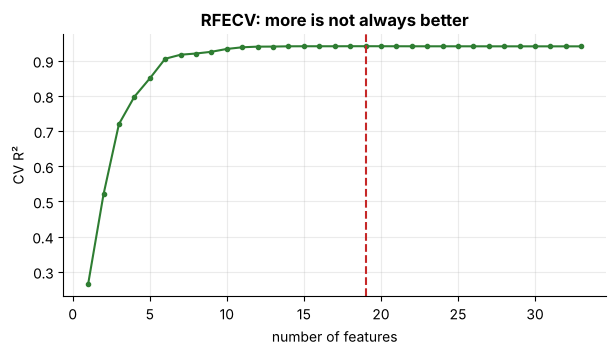

In [18]:
rfecv = RFECV(pipe, step=1, cv=5, scoring="r2", importance_getter="named_steps.ridge.coef_", n_jobs=-1).fit(X, y)
print("optimal number of features:", rfecv.n_features_)
print("selected:", X.columns[rfecv.support_].tolist())

scores = rfecv.cv_results_["mean_test_score"]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(1, len(scores) + 1), scores, marker="o", ms=3); ax.axvline(rfecv.n_features_, color="#C62828", ls="--")
ax.set_xlabel("number of features"); ax.set_ylabel("CV R²"); ax.set_title("RFECV: more is not always better"); plt.show()

The curve rises steeply, then flattens: after about a dozen features we're only adding noise or repeating ourselves. **Pick the smallest set near the top of the curve**: simpler is easier to maintain.

---
# Part 6 · Feature importance (embedded methods)

## 6.1 Tree importance: impurity vs permutation
Random forests report how much each feature reduced impurity (`feature_importances_`). Faster, but *biased*. **Permutation importance** shuffles one feature in the **test** set and measures how much the score drops: a direct "how much does the model rely on this?"

RF test R² = 0.929


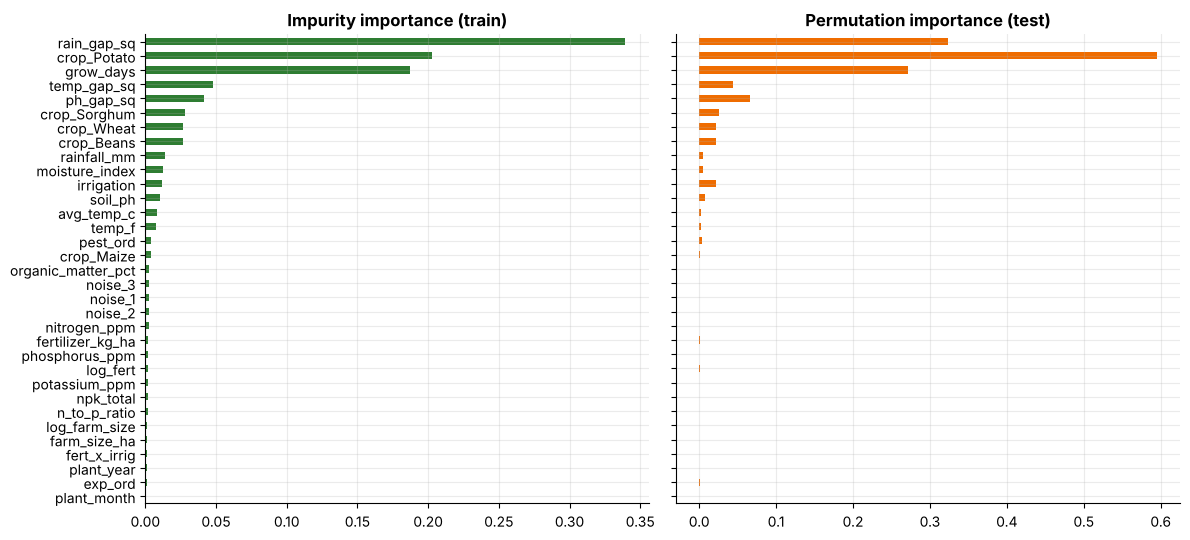

noise features → impurity: [0.0025, 0.0023, 0.0027] | permutation: [-0.0002, 0.0004, 0.0001]


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)
rf = RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=0).fit(X_tr, y_tr)
print(f"RF test R² = {rf.score(X_te, y_te):.3f}")

imp  = pd.Series(rf.feature_importances_, index=X.columns)
perm = pd.Series(permutation_importance(rf, X_te, y_te, n_repeats=10, random_state=0, n_jobs=-1).importances_mean, index=X.columns)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
order = imp.sort_values().index
imp[order].plot.barh(ax=ax[0], color="#2E7D32", title="Impurity importance (train)")
perm[order].plot.barh(ax=ax[1], color="#EF6C00", title="Permutation importance (test)")
plt.tight_layout(); plt.show()
print("noise features → impurity:", imp[["noise_1", "noise_2", "noise_3"]].round(4).tolist(), "| permutation:", perm[["noise_1", "noise_2", "noise_3"]].round(4).tolist())

Impurity importance gives the noise columns small *positive* credit (trees can always carve up noise on training data); permutation importance puts them at or near **zero** (shuffling something useless can't hurt). When the two disagree, trust permutation importance on held-out data.

> ⚠️ **Correlated features share credit.** If `temp_f` and `avg_temp_c` are both present, importance is split between them and each looks half as important as it is. Prune redundancy first.

## 6.2 Lasso: selection by shrinkage
L1 regularisation pushes useless coefficients to **exactly zero**, automatically selecting features while fitting.

In [20]:
from sklearn.linear_model import LassoCV
from sklearn.feature_selection import SelectFromModel

lasso_pipe = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0))
lasso_pipe.fit(X_tr, y_tr)
coef = pd.Series(lasso_pipe[-1].coef_, index=X.columns)
print(f"Lasso test R² = {lasso_pipe.score(X_te, y_te):.3f} | features kept: {(coef != 0).sum()} of {len(coef)}")
print("Set to zero:", coef[coef == 0].index.tolist())

Lasso test R² = 0.941 | features kept: 20 of 33
Set to zero: ['avg_temp_c', 'soil_ph', 'nitrogen_ppm', 'potassium_ppm', 'plant_month', 'grow_days', 'npk_total', 'fert_x_irrig', 'crop_Wheat', 'noise_1', 'noise_2', 'noise_3', 'temp_f']


Now let's gather all our opinions in one table. A feature chosen by *several independent methods* is a safe bet; one chosen by only one deserves suspicion.

In [21]:
top = lambda s, k=12: set(s.sort_values(ascending=False).head(k).index)
votes = pd.DataFrame({
    "mutual info": pd.Series(1, index=list(top(MI))),
    "RFECV":       pd.Series(1, index=X.columns[rfecv.support_]),
    "permutation": pd.Series(1, index=list(top(perm))),
    "lasso ≠ 0":   pd.Series(1, index=coef[coef != 0].index),
}).reindex(X.columns).fillna(0).astype(int)
votes["total votes"] = votes.sum(axis=1)
votes.sort_values("total votes", ascending=False).head(14)

,mutual info,RFECV,permutation,lasso ≠ 0,total votes
rainfall_mm,1,1,1,1,4
moisture_index,1,1,1,1,4
crop_Beans,1,1,1,1,4
crop_Potato,1,1,1,1,4
crop_Sorghum,1,1,1,1,4
ph_gap_sq,1,1,1,1,4
temp_gap_sq,1,1,1,1,4
rain_gap_sq,1,1,1,1,4
irrigation,0,1,1,1,3
crop_Maize,1,1,0,1,3


---
# Part 7 · Dimensionality reduction with PCA

Selection *keeps or drops* columns. **PCA** (Principal Component Analysis) *builds new columns* (each a weighted blend of the originals) ordered by how much variation they capture, and mutually uncorrelated.

**Dataset:** `soil_spectra.csv`: 40 near-infrared reflectance bands measured on soil samples, used to predict organic carbon. Neighbouring wavelengths behave almost identically: perfect PCA territory.

(700, 40)


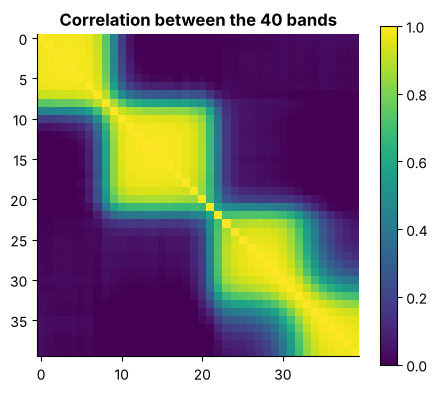

average |correlation| between different bands: 0.32


In [22]:
spectra = load_spectra()
bands = spectra.filter(like="band_")
target = spectra["organic_carbon_pct"]
print(bands.shape)

bc = bands.corr()
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(bc, cmap="viridis", vmin=0, vmax=1); ax.grid(False); plt.colorbar(im)
ax.set_title("Correlation between the 40 bands"); plt.show()
print(f"average |correlation| between different bands: {(bc.abs().values[np.triu_indices(40, 1)]).mean():.2f}")

### 7.1 Fit PCA and read the *scree plot*
**Always standardise first**: PCA chases variance, and large-scale columns would dominate.

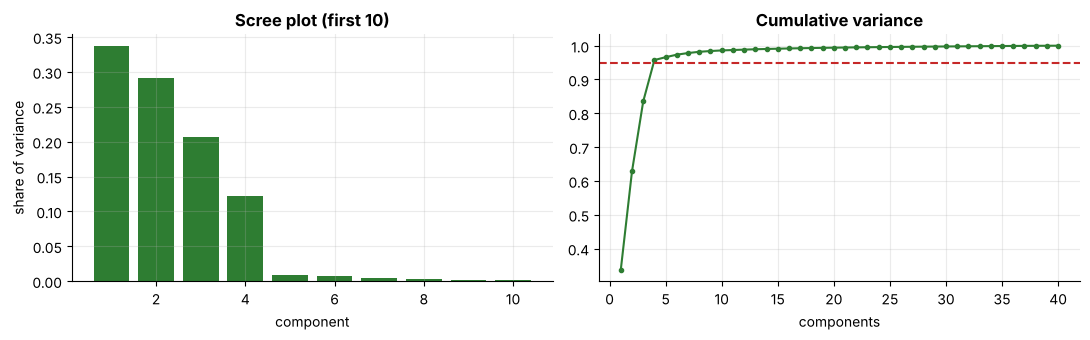

90% of the variance → 4 components (out of 40)
95% of the variance → 4 components (out of 40)
99% of the variance → 14 components (out of 40)


In [23]:
from sklearn.decomposition import PCA

Zs = StandardScaler().fit_transform(bands)
pca = PCA().fit(Zs)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(1, 11), evr[:10]); ax[0].set_title("Scree plot (first 10)"); ax[0].set_xlabel("component"); ax[0].set_ylabel("share of variance")
ax[1].plot(range(1, 41), cum, marker="o", ms=3); ax[1].axhline(0.95, color="#C62828", ls="--"); ax[1].set_title("Cumulative variance"); ax[1].set_xlabel("components")
plt.tight_layout(); plt.show()

for t in (0.90, 0.95, 0.99):
    print(f"{t:.0%} of the variance → {int(np.argmax(cum >= t)) + 1} components (out of 40)")

The first handful of components carry nearly everything. The sharp 'elbow' in the scree plot tells us the data is *effectively* low-dimensional. A common rule: keep enough components for **90–99%** of the variance, or until the cross-validated score of your model stops improving.

### 7.2 What *is* a component? Look at the loadings

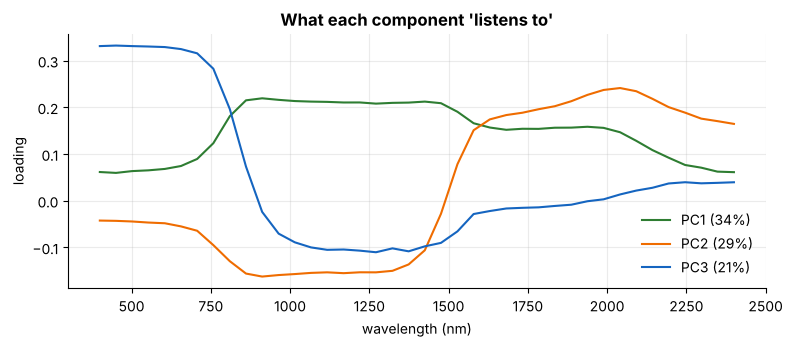

In [24]:
wl = [int(c.split("_")[1].replace("nm", "")) for c in bands.columns]
fig, ax = plt.subplots(figsize=(9, 3.3))
for i in range(3):
    ax.plot(wl, pca.components_[i], label=f"PC{i+1} ({evr[i]:.0%})")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("loading"); ax.legend(); ax.set_title("What each component 'listens to'"); plt.show()

PC1 is a nearly flat line (it says *"overall brightness"* (all bands rising together); PC2 and PC3 are smooth waves over particular wavelength ranges. Components often have physical meaning) worth reporting.

### 7.3 Does compression cost accuracy? (PCA *inside* a pipeline)

In [25]:
res = {}
for k in [1, 2, 3, 4, 5, 8]:
    res[f"PCA {k}"] = cross_val_score(make_pipeline(StandardScaler(), PCA(k), Ridge()), bands, target, cv=5, scoring="r2").mean()
res["all 40 bands"] = cross_val_score(make_pipeline(StandardScaler(), Ridge()), bands, target, cv=5, scoring="r2").mean()
pd.Series(res).round(3).to_frame("CV R²").T

,PCA 1,PCA 2,PCA 3,PCA 4,PCA 5,PCA 8,all 40 bands
CV R²,-0.007,0.116,0.785,0.873,0.873,0.873,0.865


With ~4 components the model is as good as with all 40 bands: 10× fewer inputs, no loss, less overfitting risk. **Fit PCA on training data only** (like any learned transform). Inside a pipeline that's automatic.

| | Selection | PCA |
|---|---|---|
| Output | A *subset* of the original columns | *New* blended columns |
| Interpretable? | ✅ Yes | ⚠️ Harder |
| Handles correlated groups | Picks one | Merges them |
| Uses the target? | Usually (supervised) | ❌ No (unsupervised) |

*(t-SNE and UMAP are for visualisation, not preprocessing for models; LDA is a supervised alternative to PCA for classification.)*

---
# Part 8 · A selection playbook

1. **Drop the junk**: constant columns, impossible columns, perfect duplicates.
2. **Prune redundancy** with correlation / VIF.
3. **Filter** with mutual information (+ F-test) to get a shortlist.
4. **Confirm** with a model-aware method (RFECV, permutation importance, Lasso).
5. **Check with canaries**.
6. If still too wide and correlated → **PCA**.
7. ⚠️ **Do all of this inside cross-validation / a pipeline**: selection that peeks at all the data before splitting is a classic leak. Lesson 6 shows how dramatic the damage can be.

---
## 🧩 Practice problems
Now it is your turn. Each problem is **self-contained** (it tells you what data to load), so you can do them in any order.

**How to work like a pro:**
1. Read the problem twice. Predict the answer *before* you code.
2. Struggle for at least 10 minutes. Struggling is where learning happens.
3. Open a **hint** only when stuck - they get progressively stronger.
4. Compare with `solutions/solutions_05.ipynb` **after** you have your own answer.

Difficulty: ⭐ warm-up · ⭐⭐ core skill · ⭐⭐⭐ challenge

### Problem 5.1 &nbsp; ⭐ &nbsp; Prune redundant features

Build the feature matrix `X` (see the first code cell of the lesson - it's in the solution setup too).

1. List every pair of features with absolute correlation **above 0.9**.
2. Write a function `drop_correlated(X, threshold)` that returns the names to drop, keeping the *first* feature of each correlated pair.
3. How many features are removed? Is the Fahrenheit column among them?

<details><summary>💡 Hint 1</summary>

`corr = X.corr().abs()`; keep only the upper triangle with `np.triu(np.ones(corr.shape), k=1)`.

</details>

<details><summary>💡💡 Hint 2</summary>

`upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))`; a column is dropped if `(upper[col] > t).any()`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

For the pair list: `upper.stack()` then filter `> 0.9`.

</details>

In [26]:
# ✏️ Your code here

### Problem 5.2 &nbsp; ⭐⭐ &nbsp; The canary test

Add **five** random-noise columns (`rng = np.random.default_rng(1)`, standard normal) to the feature matrix `X`. Rank *all* features by:
(a) the F-statistic (`f_regression`) and (b) mutual information (`mutual_info_regression`, `random_state=0`).

Report (1) the ranks of the five noise columns for each method and (2) the **noise floor**: the best score any canary achieved, and how many *real* features score above it. What would you conclude about a real feature scoring below the floor?

<details><summary>💡 Hint 1</summary>

`SelectKBest(f_regression, k='all').fit(X, y).scores_` gives one score per column.

</details>

<details><summary>💡💡 Hint 2</summary>

`pd.Series(scores, index=X.columns).rank(ascending=False)` converts scores to ranks (1 = best).

</details>

<details><summary>💡💡💡 Hint 3</summary>

The noise floor is `scores[canaries].max()`; count real features with `scores[real] > floor`.

</details>

In [27]:
# ✏️ Your code here

### Problem 5.3 &nbsp; ⭐⭐ &nbsp; How many features do we really need? (RFECV)

Use `RFECV` with a *pipeline* of `StandardScaler → Ridge` (so scaling happens inside each CV fold) and 5-fold CV on `X`, `y`.

Report the optimal number of features and list the selected ones. Are the three `noise_*` columns and `temp_f` selected?

<details><summary>💡 Hint 1</summary>

`RFECV(estimator, step=1, cv=5, scoring='r2', importance_getter='named_steps.ridge.coef_')`.

</details>

<details><summary>💡💡 Hint 2</summary>

`make_pipeline(StandardScaler(), Ridge())` names its steps `standardscaler` and `ridge`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

`selector.support_` is a boolean mask; `X.columns[selector.support_]` gives the names; `selector.n_features_` the count.

</details>

In [28]:
# ✏️ Your code here

### Problem 5.4 &nbsp; ⭐⭐ &nbsp; Impurity importance vs permutation importance

Split 75/25 (`random_state=0`). Fit a `RandomForestRegressor(200, min_samples_leaf=3, random_state=0)`.

Compare for the three `noise_*` columns: the **impurity importance** (`feature_importances_`) and the **permutation importance on the test set**, each expressed as a percentage of that method's *top* feature. Which method is more fooled by noise?

<details><summary>💡 Hint 1</summary>

`from sklearn.inspection import permutation_importance`; `permutation_importance(rf, X_te, y_te, n_repeats=10, random_state=0).importances_mean`.

</details>

<details><summary>💡💡 Hint 2</summary>

Normalise: `imp / imp.max() * 100`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Look at the noise columns in both Series.

</details>

In [29]:
# ✏️ Your code here

### Problem 5.5 &nbsp; ⭐⭐⭐ &nbsp; Principal components on soil spectra

Load the soil spectra (`load_spectra()`); the features are the 40 `band_*` columns, the target `organic_carbon_pct`.

1. Standardise the bands and fit PCA. How many components are needed to explain **90%, 95% and 99%** of the variance?
2. With 5-fold CV and a pipeline `StandardScaler → PCA(k) → Ridge`, compute R² for k = 1…8. Where does it plateau?
3. Compare with Ridge on all 40 raw bands. What did PCA buy us?

<details><summary>💡 Hint 1</summary>

`PCA().fit(Xs).explained_variance_ratio_.cumsum()`; the count is `np.argmax(cum >= 0.95) + 1`.

</details>

<details><summary>💡💡 Hint 2</summary>

`cross_val_score(make_pipeline(StandardScaler(), PCA(k), Ridge()), bands, target, cv=5, scoring='r2').mean()`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

The spectra were generated from 4 underlying 'shapes': expect the curve to flatten near k = 3–4.

</details>

In [30]:
# ✏️ Your code here

---
## ✅ Check your understanding
Answer in your head first, *then* click to reveal.

**Q1.** Two features have correlation 0.98. The best action is usually to…

- **A)** Keep both: more is better
- **B)** Keep one of them
- **C)** Multiply them together
- **D)** Delete the target

<details><summary>Show answer</summary>

**B**: Near-duplicate features add noise, cost and (for linear models) unstable coefficients, but almost no information.

</details>

**Q2.** Which family does RFE belong to?

- **A)** Filter
- **B)** Wrapper
- **C)** Embedded
- **D)** Dimensionality reduction

<details><summary>Show answer</summary>

**B**: Wrappers repeatedly *train a model* on different feature subsets. Filters use statistics only; embedded methods (Lasso, trees) select during training.

</details>

**Q3.** A feature has zero correlation with the target but a perfect U-shaped relationship. A correlation filter will…

- **A)** Keep it
- **B)** Wrongly discard it: correlation only sees linear relations
- **C)** Crash
- **D)** Convert it to a ratio

<details><summary>Show answer</summary>

**B**: Pearson correlation is blind to non-linear patterns. Mutual information or tree-based importance can detect them.

</details>

**Q4.** Why must PCA be fitted on the training set only?

- **A)** PCA is slow
- **B)** Its components are learned from data: fitting on everything lets test data shape the features
- **C)** It cannot handle test data
- **D)** PCA needs labels

<details><summary>Show answer</summary>

**B**: PCA learns directions from the data. Same fit/transform logic as any other preprocessing step.

</details>

---
## 📌 Summary: what to remember
- More features can *hurt*: noise, redundancy and the curse of dimensionality.
- Filters are fast but see columns one by one; wrappers are slower but consider combinations; embedded methods select while training.
- Correlation is linear-only. Use mutual information / permutation importance to catch curves.
- Permutation importance on held-out data is more trustworthy than impurity importance.
- Plant *canary* noise columns to sanity-check any selector.
- PCA builds fewer, uncorrelated features: standardise first, fit on training data only.

## 🚧 Common mistakes
- ⚠️ Dropping a feature because its Pearson correlation is low (non-linear effects!).
- ⚠️ Keeping both members of a correlated pair, then misreading split importances.
- ⚠️ Selecting features on the full dataset *before* cross-validation (leakage).
- ⚠️ Applying PCA without scaling.

➡️ **Next:** Lesson 06: Data Leakage: how perfectly good code produces perfectly fake results.